# Exercício 3 — Robustez, Resiliência e Hierarquia em Redes Complexas
UFPR · Biologia Computacional

Este trabalho compara duas redes reais: Facebook e Western US Power Grid.
Queremos saber o que acontece com suas conexões quando alguns nós são removidos.

Execute as células em ordem. As tabelas ficam em `output/resultados/` e as
figuras em `output/graficos/`. Esses arquivos serão usados no relatório de
3 a 5 páginas, que será preparado depois, com a identificação do grupo.

Os cálculos seguem os exemplos do professor em `professor/EaD3_Script1.R`
e `professor/EaD3_Script2.R`. Os grafos pequenos usados nos testes não
substituem os dados reais.

In [1]:
from pathlib import Path
import sys
import os
import json
from importlib.metadata import version

# Funciona ao abrir o notebook na raiz ou na pasta notebooks.
RAIZ = Path.cwd().resolve()
if not (RAIZ / 'src').is_dir():
    RAIZ = RAIZ.parent
if not (RAIZ / 'professor' / 'EaD3_Script2.R').is_file():
    raise FileNotFoundError('Abra o notebook na raiz do exercício ou em notebooks/.')
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
os.environ.setdefault('MPLCONFIGDIR', str(RAIZ / '.cache' / 'matplotlib'))

import pandas as pd
from IPython.display import display, Markdown, Image
from src.carregar_redes import carregar_redes
from src.metricas import caracterizar_rede, analisar_kcore
from src.simulacao import simular_resiliencia
from src.visualizacao import plotar_rede, plotar_resiliencia, exportar_resultados

RESULTADOS = RAIZ / 'output' / 'resultados'
GRAFICOS = RAIZ / 'output' / 'graficos'
for pasta in (RESULTADOS, GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)
N_REMOCOES, N_REPETICOES, SEMENTE = 10, 5, 123
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 6)

def slug(nome):
    return nome.lower().replace(' ', '_')

versoes = {p: version(p) for p in ['igraph', 'pandas', 'matplotlib', 'nbclient', 'pytest']}
(RESULTADOS / 'parametros.json').write_text(json.dumps({
    'n_remover': N_REMOCOES, 'n_rep': N_REPETICOES, 'semente': SEMENTE,
    'python': sys.version.split()[0], 'versoes': versoes,
    'desempate': 'IDs originais em ordem de texto; por exemplo, 10 antes de 2',
    'aleatoriedade': 'random.Random(123); sample sem reposição; nova rede em cada repetição',
    'apl': 'pares alcançáveis da rede inteira; directed=False, unconn=True',
    'apl_lcc': 'pares da maior componente conectada',
}, indent=2, ensure_ascii=False), encoding='utf-8')
display(versoes)

{'igraph': '0.11.9',
 'pandas': '2.2.3',
 'matplotlib': '3.9.4',
 'nbclient': '0.10.2',
 'pytest': '8.4.2'}

## 1. Importação, limpeza e caracterização

Uma rede tem **nós** (os elementos estudados) e **arestas** (as ligações entre eles).
No Facebook, os nós representam usuários e as arestas, amizades. No Power Grid,
representam pontos da infraestrutura elétrica e as linhas que os ligam.
As duas redes são **não direcionadas**: as ligações não têm um sentido único.

Os dados vêm do [SNAP — Facebook](https://snap.stanford.edu/data/ego-Facebook.html)
e do [Network Repository — inf-power](https://networkrepository.com/inf-power.php).
O código mantém os IDs dos arquivos originais e remove ligações de um nó com
ele mesmo e ligações repetidas.

A tabela apresenta:

- **Ordem:** quantidade de nós.
- **Densidade:** proporção das ligações possíveis que existem.
- **Diâmetro:** maior distância entre dois nós, medida pelo caminho mais curto.
- **Transitividade global:** frequência com que dois vizinhos de um nó também se ligam.
- **Componentes:** grupos de nós que conseguem alcançar uns aos outros.
- **LCC:** tamanho do maior desses grupos, a maior componente conectada.

Se uma rede estiver separada em componentes, o diâmetro será calculado somente
na LCC. A coluna de componentes permite reconhecer essa situação.

In [2]:
redes = carregar_redes(RAIZ / 'data', baixar=True)
caracterizacao = pd.DataFrame([
    {'rede': nome, **caracterizar_rede(g)} for nome, g in redes.items()
])
caracterizacao.to_csv(RESULTADOS / 'caracterizacao.csv', index=False)
fontes = json.loads((RAIZ / 'data' / 'fontes.json').read_text(encoding='utf-8'))
display(caracterizacao)
display(fontes)

,rede,n_vertices,n_arestas,direcionada,densidade,diametro,transitividade_global,n_componentes,lcc
0,Facebook,4039,88234,False,0.01082,8,0.519174,1,4039
1,Power Grid,4941,6594,False,0.00054,46,0.103153,1,4941


{'Facebook': {'arquivo': 'facebook_combined.txt.gz',
  'sha256': '125e84db872eeba443d270c70315c256b0af43a502fcfe51f50621166ad035d7',
  'url': 'https://snap.stanford.edu/data/facebook_combined.txt.gz'},
 'Power Grid': {'arquivo': 'inf-power.zip',
  'sha256': 'ea5aac207591d6dd863f470641a617aa87059a923282bea9d969335a9904f606',
  'url': 'https://nrvis.com/download/data/inf/inf-power.zip'}}

## 2. Decomposição K-core

Um subgrafo é uma parte da rede. O **grau** de um nó é a quantidade de ligações que ele tem. Um **k-core** é o
maior subgrafo em que cada nó tem pelo menos `k` ligações com outros nós desse
mesmo subgrafo. Para encontrá-lo, retiramos repetidamente os nós de grau menor
que `k`.

O **coreness** de um nó é o maior valor de `k` de um núcleo ao qual ele pertence.
O **k-max** é o maior desses valores na rede. Os nós com esse valor formam o
núcleo máximo.

Selecionamos os cinco nós de maior grau **dentro desse núcleo**. O grau relativo
é o grau interno dividido por `n-1`, sendo `n` a quantidade de nós do núcleo.
Quando há empate, ordenamos os IDs como texto: por exemplo, `10` vem antes de `2`.

Também calculamos:

- **Betweenness (intermediação):** mede a participação de um nó nos caminhos
  mais curtos entre outros nós. Um valor alto pode indicar uma ligação importante
  entre partes da rede.
- **Assortatividade de grau:** mede a tendência de nós se ligarem a outros de
  grau parecido. Valores positivos indicam essa tendência; negativos indicam
  ligações entre graus diferentes; valores próximos de zero indicam pouca
  associação entre os graus nas pontas das arestas.

Ter grau alto, intermediação alta e pertencer ao núcleo máximo são propriedades
diferentes. Calculamos a intermediação exata uma vez na rede original limpa e a
reutilizamos na simulação e nas figuras. As medidas de todos os nós são salvas em CSV.

In [3]:
nucleos = {}
resumos, maiores_graus, metricas_nos = [], [], []
for nome, g in redes.items():
    resultado = analisar_kcore(g)
    nucleos[nome] = resultado
    resumos.append({'rede': nome, **{
        k: resultado[k] for k in ['kmax', 'n_kmax', 'densidade_kmax', 'assortatividade']
    }})
    maiores_graus.append(resultado['top5'].assign(rede=nome))
    metricas_nos.append(pd.DataFrame({
        'rede': nome, 'id_original': g.vs['name'], 'grau': g.degree(),
        'coreness': g.vs['coreness'], 'betweenness': g.vs['betweenness'],
        'no_kmax_original': [c == resultado['kmax'] for c in g.vs['coreness']],
    }))
resumo_nucleos = pd.DataFrame(resumos)
top5 = pd.concat(maiores_graus, ignore_index=True)
metricas_nos = pd.concat(metricas_nos, ignore_index=True)
resumo_nucleos.to_csv(RESULTADOS / 'nucleos.csv', index=False)
top5.to_csv(RESULTADOS / 'top5_nucleo.csv', index=False)
metricas_nos.to_csv(RESULTADOS / 'metricas_nos.csv', index=False)
display(resumo_nucleos)
display(top5)

,rede,kmax,n_kmax,densidade_kmax,assortatividade
0,Facebook,115,158,0.898492,0.063577
1,Power Grid,5,12,0.545455,0.003457


,id_original,grau_interno,grau_relativo,rede
0,1912,157,1.000000,Facebook
1,2206,157,1.000000,Facebook
2,2340,157,1.000000,Facebook
3,2507,157,1.000000,Facebook
4,2088,156,0.993631,Facebook
5,4353,7,0.636364,Power Grid
6,4382,7,0.636364,Power Grid
7,4403,7,0.636364,Power Grid
8,4333,6,0.545455,Power Grid
9,4385,6,0.545455,Power Grid


## 3. Simulação de ataques e falhas

Seguimos o Script 2 do professor:

- **Ataque direcionado:** removemos os dez nós com maior intermediação inicial,
  um por vez. A lista de alvos fica fixa durante o ataque.
- **Falha aleatória:** sorteamos dez nós diferentes e os removemos um por vez.
  Repetimos esse processo cinco vezes, sempre recomeçando na rede original,
  e calculamos a média dos resultados de cada passo.

A semente `123` permite repetir os sorteios no Python. Os nós sorteados não
precisam ser os mesmos do R, pois as duas linguagens usam sorteadores diferentes.
O passo zero registra a situação antes das remoções. Os IDs originais permitem
localizar os nós mesmo quando o igraph muda a numeração interna.

Após cada remoção, medimos a LCC e recalculamos o coreness. Guardamos duas
medidas de **caminho médio**, expressas em quantidade de ligações percorridas:

- `apl`: média entre os pares de nós que ainda conseguem se alcançar, em toda
  a rede. Os pares sem caminho são ignorados, como no exemplo do professor.
- `apl_lcc`: média calculada somente dentro da LCC.

As duas medidas ficam em colunas e gráficos separados. Os cálculos são exatos
e podem levar alguns minutos.

In [4]:
todos_detalhes, todas_medias, todos_alvos = [], [], []
for nome, g in redes.items():
    print(f'Simulando {nome}...', flush=True)
    detalhes_rede, medias_rede, alvos_rede = simular_resiliencia(
        g, nome, n_remover=N_REMOCOES, n_rep=N_REPETICOES, semente=SEMENTE
    )
    todos_detalhes.append(detalhes_rede)
    todas_medias.append(medias_rede)
    todos_alvos.append(alvos_rede)
detalhes = pd.concat(todos_detalhes, ignore_index=True)
medias = pd.concat(todas_medias, ignore_index=True)
alvos = pd.concat(todos_alvos, ignore_index=True)
exportar_resultados(detalhes, medias, alvos, RESULTADOS)
display(alvos)
display(medias[medias['passo'].isin([0, N_REMOCOES])])

Simulando Facebook...


Simulando Power Grid...


,rede,ordem,id_original,betweenness,coreness,no_kmax_original
0,Facebook,1,107,3.916560e+06,70,False
1,Facebook,2,1684,2.753287e+06,43,False
2,Facebook,3,3437,1.924506e+06,22,False
3,Facebook,4,1912,1.868918e+06,115,True
4,Facebook,5,1085,1.214578e+06,22,False
5,Facebook,6,0,1.192496e+06,21,False
6,Facebook,7,698,9.400242e+05,17,False
7,Facebook,8,567,7.849969e+05,31,False
8,Facebook,9,58,6.875950e+05,6,False
9,Facebook,10,428,5.241641e+05,31,False


,rede,estrategia,passo,n_vertices,lcc,lcc_frac,apl,apl_lcc,kmax,n_kmax
0,Facebook,Ataque direcionado,0,4039.0,4039.0,1.000000,3.692507,3.692507,115.0,158.0
10,Facebook,Ataque direcionado,10,4029.0,3220.0,0.797227,4.842216,4.889043,114.0,157.0
11,Facebook,Falha aleatória,0,4039.0,4039.0,1.000000,3.692507,3.692507,115.0,158.0
21,Facebook,Falha aleatória,10,4029.0,4029.0,0.997524,3.693146,3.693146,115.0,158.0
22,Power Grid,Ataque direcionado,0,4941.0,4941.0,1.000000,18.989185,18.989185,5.0,12.0
32,Power Grid,Ataque direcionado,10,4931.0,4930.0,0.997774,24.593551,24.593551,5.0,12.0
33,Power Grid,Falha aleatória,0,4941.0,4941.0,1.000000,18.989185,18.989185,5.0,12.0
43,Power Grid,Falha aleatória,10,4931.0,4928.0,0.997369,19.053611,19.053612,5.0,12.0


In [5]:
# Confere os passos, as remoções e os tamanhos medidos nas duas redes.
assert len(detalhes) == len(redes) * (N_REMOCOES + 1) * (N_REPETICOES + 1)
assert len(medias) == len(redes) * (N_REMOCOES + 1) * 2
assert len(alvos) == len(redes) * N_REMOCOES
for (nome, estrategia, repeticao), grupo in detalhes.groupby(['rede', 'estrategia', 'repeticao']):
    grupo = grupo.sort_values('passo')
    n_original = redes[nome].vcount()
    assert grupo['passo'].tolist() == list(range(N_REMOCOES + 1))
    assert grupo['n_vertices'].tolist() == [n_original - i for i in range(N_REMOCOES + 1)]
    assert (grupo['lcc'].diff().dropna() <= 0).all()
    assert (grupo['kmax'].diff().dropna() <= 0).all()
    assert grupo.loc[grupo['passo'] > 0, 'id_removido'].nunique() == N_REMOCOES
    assert set(grupo['id_removido'].dropna()).issubset(set(redes[nome].vs['name']))
    assert (grupo['lcc_frac'] - grupo['lcc'] / n_original).abs().max() < 1e-12
print(f'Validados: {len(detalhes)} registros, {len(medias)} médias e {len(alvos)} alvos.')

Validados: 132 registros, 44 médias e 20 alvos.


## 4. Visualizações

Nas figuras das redes, a cor indica o coreness, o tamanho dos nós é ajustado
pela intermediação e o contorno destaca o núcleo máximo. Usamos transparência
e evitamos escrever o ID de cada nó para facilitar a leitura.

As curvas comparam o ataque com a média das cinco falhas. Os gráficos
individuais de k-max e tamanho do núcleo têm dois painéis: o primeiro usa uma
escala comum às duas redes; o segundo amplia o eixo vertical da própria rede.
Assim, uma mudança de uma unidade também fica visível.

Nos comparativos de núcleo, dividimos cada valor pelo seu valor inicial.
Um valor igual a `1` indica o valor inicial; `0,9` indica 90% dele. O caminho
médio da rede inteira e o da LCC continuam em figuras separadas.

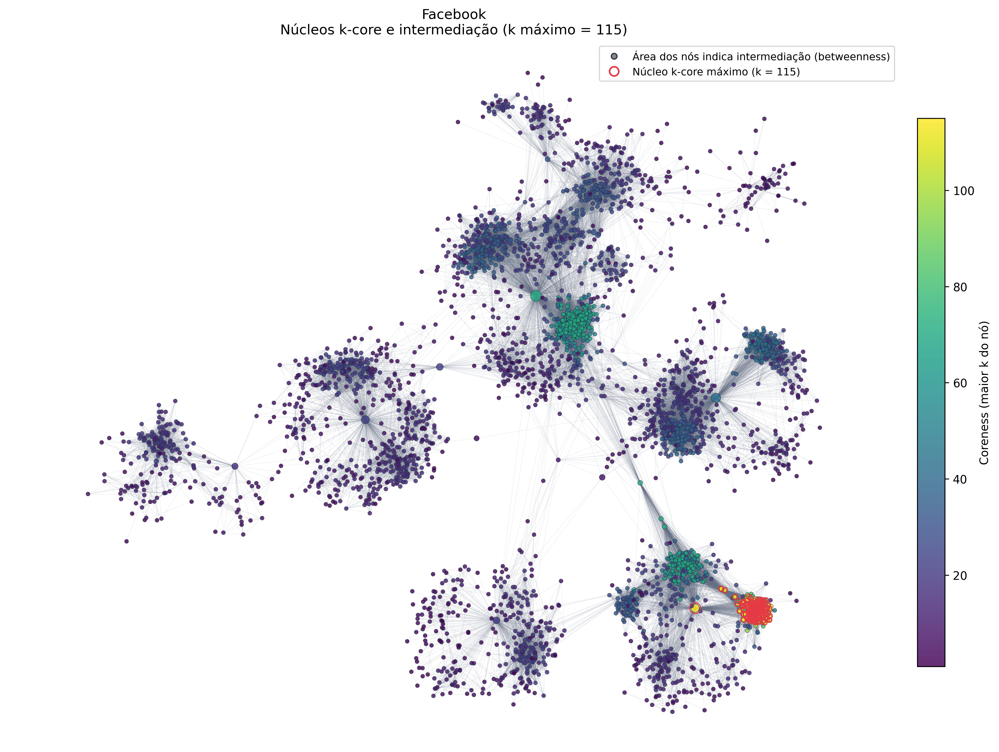

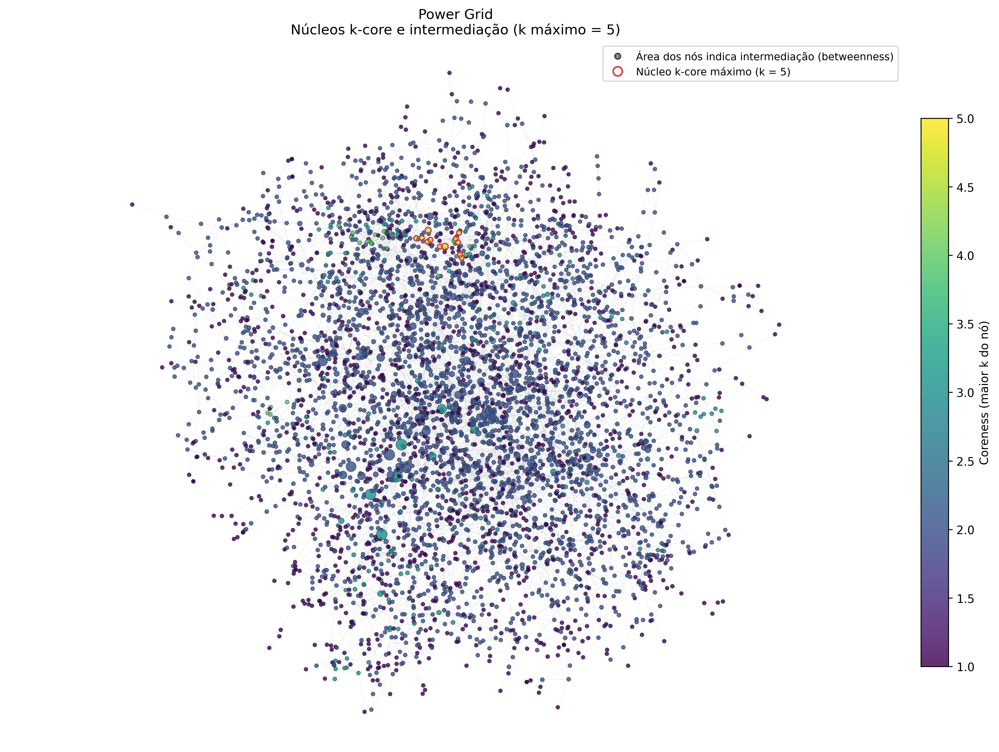

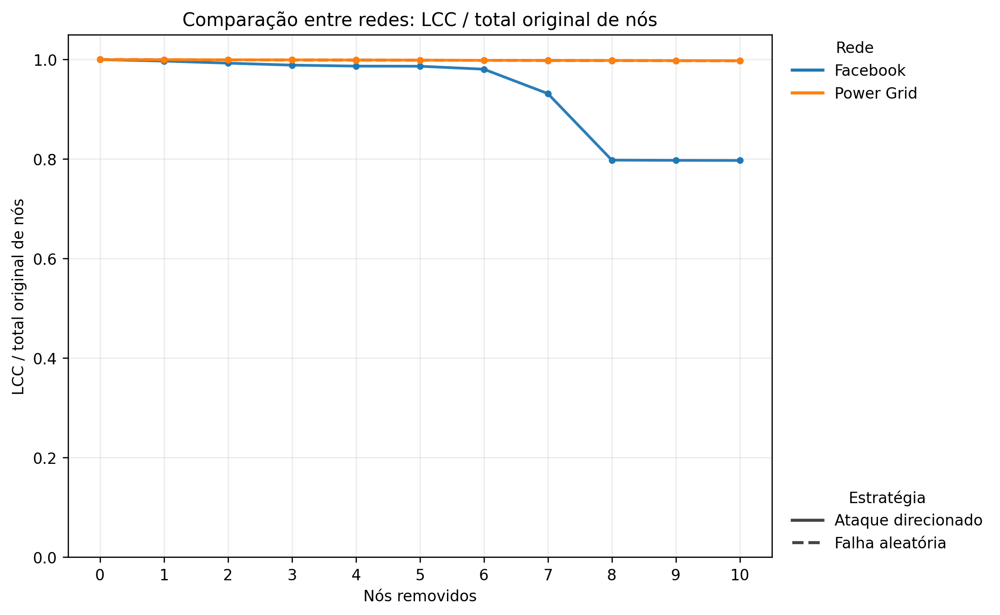

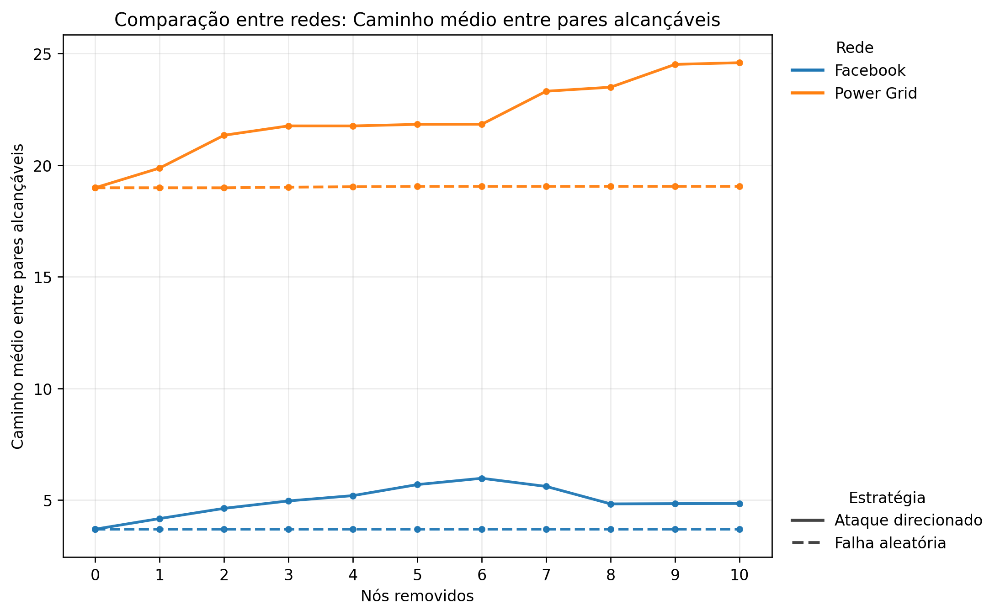

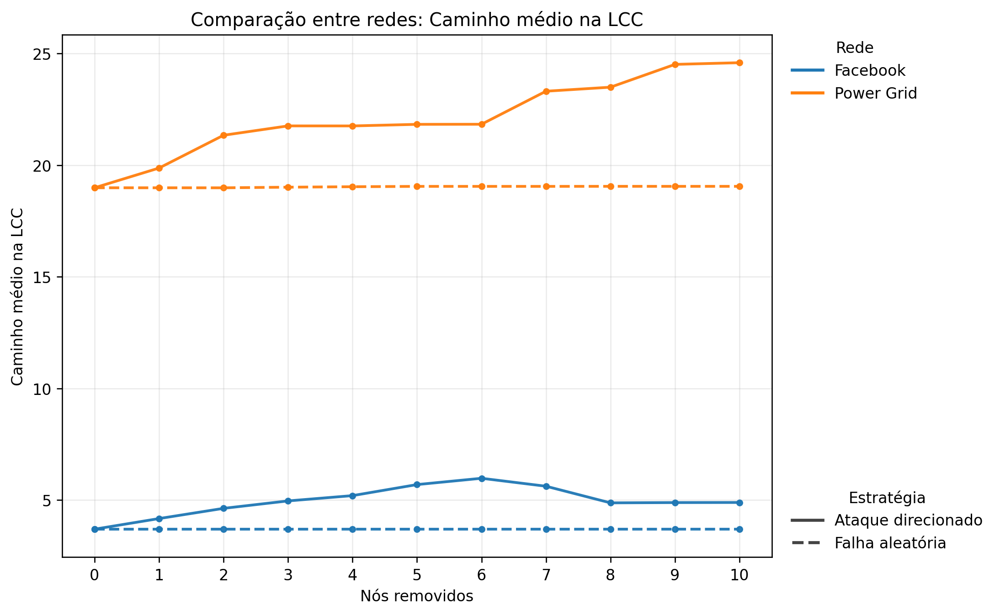

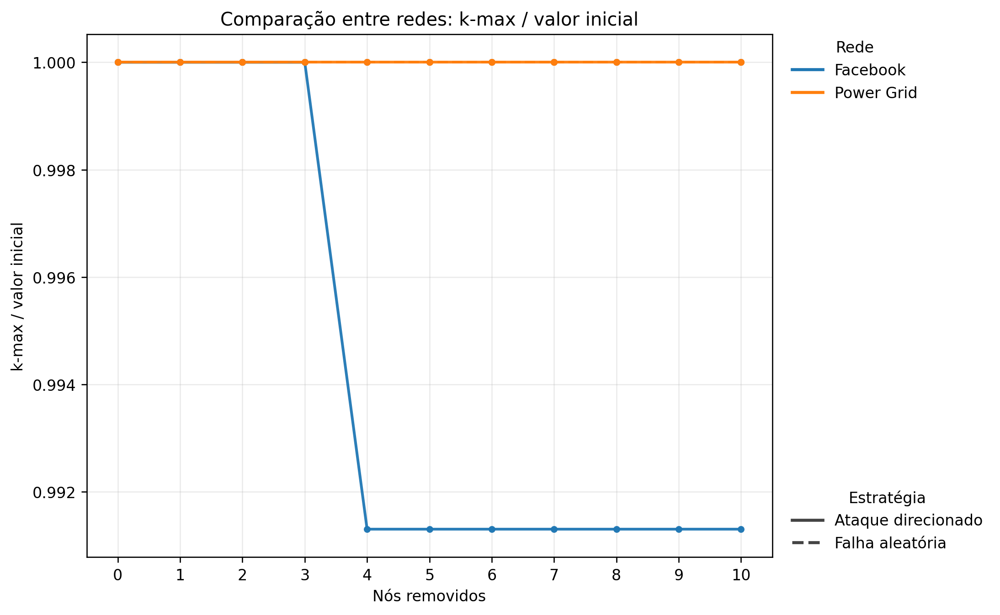

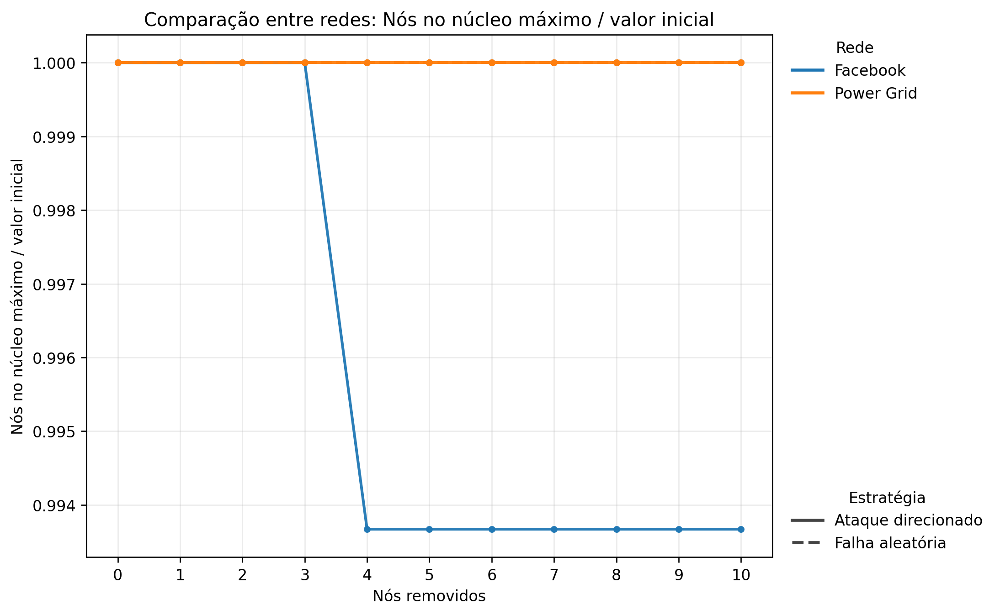

17 figuras PNG salvas em output/graficos/.


In [6]:
figuras_rede = []
for nome, g in redes.items():
    arquivo = plotar_rede(g, nome, GRAFICOS / f'{slug(nome)}_kcore.png', semente=SEMENTE)
    figuras_rede.append(arquivo)
    display(Image(filename=str(arquivo), width=800))
figuras_resiliencia = plotar_resiliencia(medias, GRAFICOS)
for arquivo in figuras_resiliencia:
    if arquivo.name.startswith('comparativo_'):
        display(Image(filename=str(arquivo), width=800))
print(f'{len(figuras_rede) + len(figuras_resiliencia)} figuras PNG salvas em output/graficos/.')

### Por que as curvas do núcleo quase não mudam?

Conferimos os CSVs reconstruindo a rede após cada remoção. Também verificamos
os núcleos por uma segunda forma de cálculo: remover repetidamente os nós com
grau menor que `k`.

| Facebook | k-max | Nós no núcleo máximo |
| --- | ---: | ---: |
| Ataque, passos 0 a 3 | 115 | 158 |
| Ataque, passos 4 a 10 | 114 | 157 |
| Cada uma das cinco falhas, em todos os passos | 115 | 158 |

O nó `1912`, removido no passo 4, é o único dos dez alvos que estava no núcleo
original. Ele se ligava aos outros 157 membros do núcleo. Ao removê-lo,
o menor grau interno cai de 115 para 114. Os 157 membros restantes formam o
novo núcleo máximo.

Nas cinco falhas aleatórias, nenhum nó sorteado pertencia ao núcleo original.
Por isso, suas ligações internas e os valores 115 e 158 foram preservados.
A escala comum quase escondia a pequena queda do ataque. O painel da direita
mostra o detalhe, mas a queda continua sendo de **apenas uma unidade**.

![Facebook: k-max e detalhe da mudança](../output/graficos/facebook_kmax.png)

![Facebook: tamanho do núcleo e detalhe da mudança](../output/graficos/facebook_n_kmax.png)

Ao final do ataque, os 157 membros restantes ainda estão na LCC de 3.220 nós.
Outras partes se separaram: a LCC caiu 20,28%, mesmo com o núcleo quase
preservado. Portanto, o núcleo pode continuar forte enquanto a conexão entre
partes da rede piora.

No Power Grid, nenhuma remoção atingiu o núcleo original. O k-max ficou em 5,
com 12 membros, em todos os passos. Esses números constantes não significam
que todos os outros nós da rede mantiveram seu coreness.

Os detalhes da conferência estão em `output/resultados/revisao_dados.md`.

## 5. Comparação e diagnóstico estrutural

A próxima tabela compara o passo zero com o passo dez. A redução da LCC é
medida em relação ao seu tamanho inicial. A coluna `fora_lcc_final` conta os
nós que sobraram, mas ficaram fora da LCC; nas falhas, mostra a média das cinco
repetições. A perda de nós da LCC inclui os nós removidos e os que ficaram
separados do maior grupo.

Para ler os resultados:

- Um núcleo pode ganhar membros quando k-max diminui, porque a exigência de
  grau ficou menor. Isso, sozinho, não indica uma melhora.
- O caminho médio pode cair quando partes da rede se separam: os pares que
  deixaram de se alcançar saem da média. Isso também não indica uma melhora.
- As dez remoções mostram apenas uma pequena parte do comportamento possível
  dessas redes. Não observamos um colapso total em nenhuma delas.
- No Power Grid, estudamos apenas as conexões entre os pontos da rede. Não
  calculamos fluxo de energia, sobrecarga ou uma falha elétrica real.

In [7]:
linhas = []
for (nome, estrategia), grupo in medias.groupby(['rede', 'estrategia']):
    inicial = grupo.loc[grupo['passo'] == 0].iloc[0]
    final = grupo.loc[grupo['passo'] == N_REMOCOES].iloc[0]
    final_detalhes = detalhes[(detalhes['rede'] == nome) &
                              (detalhes['estrategia'] == estrategia) &
                              (detalhes['passo'] == N_REMOCOES)]
    linhas.append({
        'rede': nome, 'estrategia': estrategia,
        'lcc_frac_inicial': inicial['lcc_frac'], 'lcc_frac_final': final['lcc_frac'],
        'reducao_proporcional_lcc': 1 - final['lcc_frac'] / inicial['lcc_frac'],
        'fora_lcc_final': (final_detalhes['n_vertices'] - final_detalhes['lcc']).mean(),
        'apl_inicial': inicial['apl'], 'apl_final': final['apl'],
        'apl_lcc_inicial': inicial['apl_lcc'], 'apl_lcc_final': final['apl_lcc'],
        'kmax_inicial': inicial['kmax'], 'kmax_final': final['kmax'],
        'n_kmax_inicial': inicial['n_kmax'], 'n_kmax_final': final['n_kmax'],
    })
diagnostico = pd.DataFrame(linhas)
alvos_no_nucleo = alvos.groupby('rede', as_index=False)['no_kmax_original'].sum().rename(
    columns={'no_kmax_original': 'alvos_no_kmax_original'}
)
comparacao = caracterizacao.merge(resumo_nucleos, on='rede').merge(alvos_no_nucleo, on='rede')
comparacao.to_csv(RESULTADOS / 'comparacao_estrutural.csv', index=False)
diagnostico.to_csv(RESULTADOS / 'diagnostico_resiliencia.csv', index=False)
display(comparacao)
display(diagnostico)

,rede,n_vertices,n_arestas,direcionada,densidade,diametro,transitividade_global,n_componentes,lcc,kmax,n_kmax,densidade_kmax,assortatividade,alvos_no_kmax_original
0,Facebook,4039,88234,False,0.01082,8,0.519174,1,4039,115,158,0.898492,0.063577,1
1,Power Grid,4941,6594,False,0.00054,46,0.103153,1,4941,5,12,0.545455,0.003457,0


,rede,estrategia,lcc_frac_inicial,lcc_frac_final,reducao_proporcional_lcc,fora_lcc_final,apl_inicial,apl_final,apl_lcc_inicial,apl_lcc_final,kmax_inicial,kmax_final,n_kmax_inicial,n_kmax_final
0,Facebook,Ataque direcionado,1.0,0.797227,0.202773,809.0,3.692507,4.842216,3.692507,4.889043,115.0,114.0,158.0,157.0
1,Facebook,Falha aleatória,1.0,0.997524,0.002476,0.0,3.692507,3.693146,3.692507,3.693146,115.0,115.0,158.0,158.0
2,Power Grid,Ataque direcionado,1.0,0.997774,0.002226,1.0,18.989185,24.593551,18.989185,24.593551,5.0,5.0,12.0,12.0
3,Power Grid,Falha aleatória,1.0,0.997369,0.002631,3.0,18.989185,19.053611,18.989185,19.053612,5.0,5.0,12.0,12.0


In [8]:
# Escreve o resumo usando os valores calculados acima.
def numero(valor, casas=2):
    return f"{valor:.{casas}f}".replace('.', ',')

maior_k = resumo_nucleos.loc[resumo_nucleos['kmax'].idxmax()]
mais_denso = resumo_nucleos.loc[resumo_nucleos['densidade_kmax'].idxmax()]
textos = [
    f"**Maior k-max:** {maior_k['rede']} ({int(maior_k['kmax'])}).",
    f"**Núcleo mais denso:** {mais_denso['rede']}, com "
    f"{numero(mais_denso['densidade_kmax'] * 100)}% das ligações possíveis entre seus membros.",
]
for nome in redes:
    estrutura = comparacao[comparacao['rede'] == nome].iloc[0]
    resumo = diagnostico[diagnostico['rede'] == nome].set_index('estrategia')
    ataque = resumo.loc['Ataque direcionado']
    falha = resumo.loc['Falha aleatória']
    diferenca = ataque['reducao_proporcional_lcc'] - falha['reducao_proporcional_lcc']
    if diferenca > 1e-12:
        observacao = 'O ataque reduziu mais a LCC.'
    elif diferenca < -1e-12:
        observacao = 'As falhas reduziram um pouco mais a LCC, na média.'
    else:
        observacao = 'As duas estratégias tiveram a mesma redução da LCC.'
    n_fora = int(ataque['fora_lcc_final'])
    unidade = 'nó' if n_fora == 1 else 'nós'
    textos.append(
        f"**{nome}:** assortatividade {numero(estrutura['assortatividade'], 6)}; "
        f"Alvos no núcleo original: {int(estrutura['alvos_no_kmax_original'])} de {N_REMOCOES}. "
        f"Redução da LCC: {numero(ataque['reducao_proporcional_lcc'] * 100)}% no ataque e "
        f"{numero(falha['reducao_proporcional_lcc'] * 100)}% na média das falhas. {observacao} "
        f"Fora da LCC ao final do ataque: {n_fora} {unidade}; "
        f"nas falhas, a média foi {numero(falha['fora_lcc_final'], 1)}. "
        f"Caminho médio da rede no ataque: {numero(ataque['apl_inicial'], 3)} → "
        f"{numero(ataque['apl_final'], 3)}. Caminho médio na LCC: "
        f"{numero(ataque['apl_lcc_inicial'], 3)} → {numero(ataque['apl_lcc_final'], 3)}."
    )
    curva = medias[(medias['rede'] == nome) &
                   (medias['estrategia'] == 'Ataque direcionado')].sort_values('passo')
    pico = curva.loc[curva['apl'].idxmax()]
    aumento = pico['apl'] / curva.iloc[0]['apl'] - 1
    textos.append(
        f"**Pico do caminho médio — {nome} (ataque):** o maior valor foi "
        f"{numero(pico['apl'], 3)}, no passo {int(pico['passo'])}, "
        f"um aumento de {numero(aumento * 100)}% em relação ao início. "
        f"Nesse passo, a LCC ainda tinha {numero(pico['lcc_frac'] * 100)}% dos nós originais."
    )
    if nome == 'Facebook':
        perdas = curva.assign(queda_lcc=-curva['lcc'].diff())
        maiores = perdas.nlargest(2, 'queda_lcc').sort_values('passo')
        passos = ' e '.join(str(int(p)) for p in maiores['passo'])
        textos.append(
            f"No Facebook, o pico do caminho médio veio antes das maiores quedas da LCC, "
            f"nos passos {passos}. Depois, o caminho médio caiu. Parte dessa queda pode "
            f"acontecer porque pares que ficaram separados deixaram de entrar na média. "
            f"A queda do caminho médio, nesse caso, não significa que a rede se recuperou."
        )

pior = diagnostico.loc[diagnostico['reducao_proporcional_lcc'].idxmax()]
textos.append(
    f"**Maior redução da LCC observada:** {pior['rede']}, {pior['estrategia']}, "
    f"com {numero(pior['reducao_proporcional_lcc'] * 100)}%."
)
textos.append(
    'Pelo tamanho da LCC, o Power Grid resistiu melhor ao ataque estudado. '
    'Nas falhas aleatórias, as duas redes tiveram perdas pequenas; a média de perda '
    'do Power Grid foi um pouco maior. O resultado depende da medida usada e '
    'destas dez remoções. Não houve colapso total em nenhuma rede.'
)
display(Markdown('\n\n'.join(textos)))
display(pd.DataFrame({'arquivo': [p.relative_to(RAIZ).as_posix()
                                 for p in sorted(RESULTADOS.glob('*'))]}))

**Maior k-max:** Facebook (115).

**Núcleo mais denso:** Facebook, com 89,85% das ligações possíveis entre seus membros.

**Facebook:** assortatividade 0,063577; Alvos no núcleo original: 1 de 10. Redução da LCC: 20,28% no ataque e 0,25% na média das falhas. O ataque reduziu mais a LCC. Fora da LCC ao final do ataque: 809 nós; nas falhas, a média foi 0,0. Caminho médio da rede no ataque: 3,693 → 4,842. Caminho médio na LCC: 3,693 → 4,889.

**Pico do caminho médio — Facebook (ataque):** o maior valor foi 5,973, no passo 6, um aumento de 61,76% em relação ao início. Nesse passo, a LCC ainda tinha 98,07% dos nós originais.

No Facebook, o pico do caminho médio veio antes das maiores quedas da LCC, nos passos 7 e 8. Depois, o caminho médio caiu. Parte dessa queda pode acontecer porque pares que ficaram separados deixaram de entrar na média. A queda do caminho médio, nesse caso, não significa que a rede se recuperou.

**Power Grid:** assortatividade 0,003457; Alvos no núcleo original: 0 de 10. Redução da LCC: 0,22% no ataque e 0,26% na média das falhas. As falhas reduziram um pouco mais a LCC, na média. Fora da LCC ao final do ataque: 1 nó; nas falhas, a média foi 3,0. Caminho médio da rede no ataque: 18,989 → 24,594. Caminho médio na LCC: 18,989 → 24,594.

**Pico do caminho médio — Power Grid (ataque):** o maior valor foi 24,594, no passo 10, um aumento de 29,51% em relação ao início. Nesse passo, a LCC ainda tinha 99,78% dos nós originais.

**Maior redução da LCC observada:** Facebook, Ataque direcionado, com 20,28%.

Pelo tamanho da LCC, o Power Grid resistiu melhor ao ataque estudado. Nas falhas aleatórias, as duas redes tiveram perdas pequenas; a média de perda do Power Grid foi um pouco maior. O resultado depende da medida usada e destas dez remoções. Não houve colapso total em nenhuma rede.

,arquivo
0,output/resultados/caracterizacao.csv
1,output/resultados/comparacao_estrutural.csv
2,output/resultados/diagnostico_resiliencia.csv
3,output/resultados/metricas_nos.csv
4,output/resultados/nucleos.csv
5,output/resultados/parametros.json
6,output/resultados/resiliencia_alvos.csv
7,output/resultados/resiliencia_detalhes.csv
8,output/resultados/resiliencia_medias.csv
9,output/resultados/revisao_dados.md


### O que os domínios e a assortatividade ajudam a entender?

As duas redes representam relações diferentes. O Facebook registra amizades;
o Power Grid registra ligações entre pontos da infraestrutura elétrica.
Por isso, a comparação envolve formas diferentes de conexão.

No Facebook, a assortatividade é **0,063577**. Ela é positiva, mas pequena:
há uma tendência fraca de ligação entre nós de grau parecido. No Power Grid,
o valor **0,003457** fica ainda mais perto de zero. Nesse caso, há pouca
associação entre os graus dos nós ligados. Esses valores, sozinhos, não
comprovam a existência de um grupo de nós muito conectados que só se ligam entre si.

O Facebook também tem maior transitividade global (**0,519174**, contra
**0,103153** no Power Grid). Isso indica que as ligações entre vizinhos se
fecham com mais frequência na rede social estudada, algo compatível com
grupos de amizade. Essa observação ajuda a descrever a estrutura encontrada,
mas não prova que o domínio causou os resultados. Usamos apenas uma rede
social e uma de infraestrutura; não podemos generalizar para todas as redes
desses tipos.

### Núcleo mais denso significa rede mais resistente?

O núcleo do Facebook tem **89,85%** das ligações possíveis entre seus membros;
o do Power Grid tem **54,55%**. Mesmo assim, o Facebook perdeu mais LCC no ataque.
Um grupo pode ter muitas ligações internas e continuar unido, enquanto as
ligações que o conectam ao restante da rede são perdidas. No Facebook,
os 157 membros restantes do núcleo continuaram dentro da LCC final.

Somente **1 dos 10 alvos** do Facebook estava no núcleo máximo original; no
Power Grid, **nenhum**. A intermediação alta identifica a participação nos
caminhos entre nós, e não necessariamente o pertencimento ao núcleo mais denso.

### Conclusão

Neste experimento, o Facebook manteve a conexão entre todos os nós restantes
nas cinco falhas aleatórias, mas perdeu cerca de **20,28% da LCC** no ataque.
Isso sustenta a ideia de que essa rede pode resistir às falhas sorteadas e,
ao mesmo tempo, ser sensível à retirada de alguns nós importantes.

O Power Grid manteve quase todos os nós na LCC nas duas estratégias. O efeito
do ataque apareceu mais no caminho médio, que aumentou cerca de **29,51%**.
Assim, uma LCC grande pode continuar existindo mesmo quando os caminhos ficam
mais longos.

O núcleo mais denso do Facebook não garantiu maior resistência da rede inteira.
Para responder qual rede foi mais resistente, precisamos dizer **a qual tipo
de remoção e segundo qual medida**. Estas conclusões se limitam aos dados,
aos dez nós removidos e às cinco repetições deste trabalho.


### Referências

- Scripts do professor: `professor/EaD3_Script1.R` e `professor/EaD3_Script2.R`.
- CSARDI, Gabor; NEPUSZ, Tamas. **The igraph software package for complex network research**. InterJournal, Complex Systems, v. 1695, n. 5, p. 1–9, 2006. Disponível em: [igraph](https://igraph.org).
- McAuley, J.; Leskovec, J. **Learning to Discover Social Circles in Ego Networks**. NIPS, 2012. [Dados do Facebook no SNAP](https://snap.stanford.edu/data/ego-Facebook.html).
- Watts, D. J.; Strogatz, S. H. **Collective dynamics of small-world networks**. Nature, 393, 440–442, 1998.
- Rossi, R. A.; Ahmed, N. K. **The Network Data Repository with Interactive Graph Analytics and Visualization**. AAAI, 2015. [Dados do Power Grid](https://networkrepository.com/inf-power.php).

As fontes e os arquivos usados estão registrados em `data/fontes.json`.
O relatório PDF e a identificação do grupo serão preparados depois.